# Madad v2 – Outfit Recommendation (Fashion-CLIP + Outfit Transformer)

Continues `E0_baseline.ipynb`. Three models are run on the **same cleaned data and the same test questions**, so the comparison is fair:

| `MODEL` | What it is |
|---|---|
| `pair_mlp` | The E0 baseline (CLIP features → MLP on a pair → compatible yes/no), re-implemented in PyTorch |
| `type_aware` | **Middle model** (Vasileva et al., ECCV 2018, simplified): one embedding per item + a learned mask for every *pair of types* (shirt↔pants uses a different "view" than shirt↔shoe). Still compares 2 items at a time, but trained with contrastive loss on same-type negatives. |
| `outfit_transformer` | **New.** Takes the items the beneficiary already picked (1 or more) + the type she wants (e.g. Shoe) and returns an embedding; the best items are the nearest ones of that type. Trained with contrastive loss (InfoNCE) on many negatives at once. |

**Data fixes vs E0 (why):**
1. **Madad item types:** the 16 Madad types that exist in Polyvore (clothes, shoes, bags, hats, shawls, glasses, watches, belts, gloves), same as E0. Thobe, shemagh and abaya are not in Polyvore.
2. **Rescue generic categories:** items under "Clothing", "Men's Clothing", "Accessories", "Kids"... are typed from their title (e.g. a belt inside "Accessories").
3. **Duplicate products:** Polyvore re-uses the same product in many outfits with different `item_ID`s. Same product = same normalized title + type. This caused (a) test items already seen in training and (b) "negatives" that are actually the correct item.
4. **Same-gender negatives:** a men's shirt vs a women's heel is too easy a negative; the app filters by gender anyway.
5. **Fashion-specific CLIP** (`patrickjohncyh/fashion-clip`) instead of generic CLIP B/32.

One CONFIG cell → run all → one new row in `results/results_v2.csv`.

In [1]:
from google.colab import drive
import os

drive.mount('/content/drive', force_remount=True)
os.makedirs('/content/drive/MyDrive/fashion_recommender/Madad', exist_ok=True)
%cd /content/drive/MyDrive/fashion_recommender/Madad

Mounted at /content/drive
/content/drive/MyDrive/fashion_recommender/Madad


## CONFIG — change ONE value per experiment

| Experiment | Variable | Values |
|---|---|---|
| Model | `MODEL` | `pair_mlp` (baseline), `type_aware` (middle), `outfit_transformer` (new) |
| Image/text encoder | `CLIP_MODEL` | `openai/clip-vit-base-patch32`, `patrickjohncyh/fashion-clip`, `openai/clip-vit-large-patch14`, or `CLIP_BACKEND="open_clip"` + `hf-hub:Marqo/marqo-fashionSigLIP` |
| Data | `RESCUE_GENERIC`, `DEDUP`, `STRICT_NO_LEAK`, `NEG_SAME_GENDER` | `True` / `False` (ablation) |
| Transformer | `N_LAYERS`, `D_MODEL`, `HARD_NEG` | `2/3/4`, `128/256/512`, `0/16/32` |

**Suggested order:** V1 = `pair_mlp` + `openai/clip-vit-base-patch32` (E0 on clean data) → V2 = `pair_mlp` + fashion-clip → V3 = `outfit_transformer` + fashion-clip → ablations.

In [19]:
CONFIG = {
    "EXP_NAME": "V4_typeaware_fashionclip",
    "MODEL": "type_aware",            # "pair_mlp" | "type_aware" | "outfit_transformer"
    "CLIP_BACKEND": "hf",                   # "hf" (transformers CLIPModel) | "open_clip"
    "CLIP_MODEL": "patrickjohncyh/fashion-clip",
    "USE_TEXT": True,

    # ---- data ----
    # The 16 Madad types that exist in Polyvore (the app has 19; thobe, shemagh, abaya are not in Polyvore)
    "ALLOWED_TYPES": ["Shirt", "T-Shirt", "Sweater", "Pants", "Skirt", "Dress",
                      "Jacket", "Coat", "Shoe", "Belt", "Hat",
                      "Bag", "Shawl", "Glasses", "Watch", "Gloves"],
    "RESCUE_GENERIC": True,     # type generic categories ("Clothing", "Accessories"...) from the title
    "DEDUP": True,              # same product in many outfits -> one product id
    "STRICT_NO_LEAK": True,     # drop val/test items whose product also appears in train
    "NEG_SAME_GENDER": True,    # negatives from the same gender (harder, like the app)
    "EVAL_SAME_GENDER": False,  # True = candidates in FITB/ranking also same gender (harder test)
    "SPLIT": (0.70, 0.15, 0.15),
    "SEED": 42,
    "CUSTOM_DATA": None,        # CSV: outfit_id,item_id,type,image_path,text[,gender]

    # ---- outfit transformer ----
    "D_MODEL": 256,
    "N_HEADS": 4,
    "N_LAYERS": 3,
    "DROPOUT": 0.1,
    "MAX_CTX": 6,               # max items given as context
    "HARD_NEG": 16,             # extra same-type negatives per sample (plus all in-batch items)
    "MOD_DROPOUT": 0.15,        # randomly hide image OR text features (robust to Gemini descriptions)
    "LR": 3e-4,
    "WEIGHT_DECAY": 0.05,
    "BATCH_SIZE": 256,
    "SAMPLES_PER_OUTFIT": 4,    # training samples drawn from each outfit per epoch
    "EPOCHS": 80,
    "PATIENCE": 8,              # early stopping on validation FITB

    # ---- type-aware embedding (middle model) ----
    "TA_DIM": 128,              # embedding size
    "TA_HARD_NEG": 32,          # same-type negatives per positive pair
    "TA_LR": 5e-4,
    "TA_BATCH": 512,
    "TA_EPOCHS": 60,
    "TA_MASK_L1": 5e-4,         # keeps the type-pair masks sparse (as in the paper)

    # ---- pair MLP baseline ----
    "MLP_HIDDEN": [512, 256, 128],
    "MLP_DROPOUT": 0.3,
    "MLP_L2": 1e-3,
    "MLP_LR": 5e-4,
    "MLP_BATCH": 128,
    "NEG_RATIO": 3,
}

import random, json, math, re, hashlib
import numpy as np
from collections import defaultdict, Counter

random.seed(CONFIG["SEED"])
np.random.seed(CONFIG["SEED"])

## 1. Load dataset

In [3]:
if CONFIG["CLIP_BACKEND"] == "open_clip":
    !pip -q install open_clip_torch

from datasets import load_dataset, load_from_disk

RAW_PATH = "data/raw/polyvore"
if os.path.exists(RAW_PATH):
    dataset = load_from_disk(RAW_PATH)
else:
    dataset = load_dataset("Marqo/polyvore")
    dataset.save_to_disk(RAW_PATH)

data = dataset["data"]
print("Total items:", len(data))

Total items: 94096


## 2. Cleaning: keep only Madad item types

- Specific Polyvore categories → Madad type via `TYPE_MAP` (the category decides).
- Generic categories (`GENERIC_CATS`) → type from the item title with keyword rules; no match = dropped.
- Anything else (makeup, jewelry, bags, furniture, underwear, swimwear ...) is dropped.

In [4]:
TYPE_MAP = {
    "Shirt": ["Blouses", "Tops", "Tunics", "Men's Casual Shirts", "Men's Dress Shirts", "Men's Shirts",
              "Men's Polos"],
    "T-Shirt": ["T-Shirts", "Tank Tops", "Camisoles", "Men's T-Shirts", "Men's Tank Tops",
                "Activewear Tops", "Activewear Tank Tops", "Men's Activewear Tops"],
    "Sweater": ["Sweaters", "Cardigans", "Sweatshirts", "Hoodies", "Men's Sweaters", "Men's Hoodies",
                "Men's Sweatshirts"],
    "Pants": ["Pants", "Jeans", "Skinny Jeans", "Boyfriend Jeans", "Straight Leg Jeans", "Flared Jeans",
              "Bootcut Jeans", "Wide Leg Jeans", "Capri & Cropped Pants", "Shorts", "Leggings",
              "Men's Jeans", "Men's Casual Pants", "Men's Dress Pants", "Men's Pants", "Men's Shorts",
              "Activewear Pants", "Activewear Shorts", "Men's Activewear Pants", "Men's Activewear Shorts"],
    "Skirt": ["Skirts", "Mini Skirts", "Knee Length Skirts", "Long Skirts", "Activewear Skirts"],
    "Dress": ["Day Dresses", "Cocktail Dresses", "Dresses", "Gowns", "Wedding Dresses",
              "Rompers", "Jumpsuits"],
    "Jacket": ["Jackets", "Blazers", "Vests", "Men's Jackets", "Men's Sportcoats & Blazers", "Men's Vests",
               "Activewear Jackets", "Men's Activewear Jackets"],
    "Coat": ["Coats", "Outerwear", "Men's Coats", "Men's Outerwear"],
    "Shoe": ["Shoes", "Sandals", "Pumps", "Ankle Booties", "Sneakers", "Flats", "Boots",
             "Knee High Boots", "Over-The-Knee Boots", "Mid Calf Boots", "Loafers & Moccasins",
             "Oxfords", "Clogs", "Slippers", "Flip Flops", "Athletic Shoes", "Men's Sneakers",
             "Men's Shoes", "Men's Boots", "Men's Dress Shoes", "Men's Loafers & Moccasins",
             "Men's Work Boots", "Men's Oxfords", "Men's Athletic Shoes", "Men's Sandals",
             "Men's Slippers", "Men's Flip Flops"],
    "Belt": ["Belts", "Men's Belts"],
    "Hat": ["Hats", "Men's Hats"],
    "Shawl": ["Scarves", "Men's Scarves"],
    "Bag": ["Shoulder Bags", "Clutches", "Handbags", "Tote Bags", "Backpacks", "Messenger Bags",
            "Bags", "Briefcases", "Men's Backpacks", "Men's Bags", "Men's Messenger Bags",
            "Men's Briefcases"],
    "Glasses": ["Sunglasses", "Eyeglasses", "Eyewear", "Men's Sunglasses", "Men's Eyeglasses"],
    "Watch": ["Watches", "Men's Watches"],
    "Gloves": ["Gloves", "Men's Gloves"],
}
CATEGORY_TO_TYPE = {c: t for t, cats in TYPE_MAP.items() for c in cats}

GENERIC_CATS = {"Clothing", "Men's Clothing", "Men's Fashion", "Activewear", "Men's Activewear",
                "Juniors", "Girls", "Boys", "Kids", "Suits", "Men's Suits",
                "Accessories", "Men's Accessories"}

# words that mean "not a Madad item" even inside a generic category
EXCLUDE_RE = re.compile(
    r"\b(swim\w*|bikini|bras?|bralette|lingerie|underwear|panty|panties|thong|boxers?|briefs?|"
    r"pajamas?|pyjamas?|sleepwear|socks?|tights|hosiery|costume|necklace|earrings?|bracelet|"
    r"rings?|watch|bag|handbag|clutch|tote|backpack|wallet|purse|sunglasses|glasses|scarf|"
    r"gloves?|perfume|fragrance|lipstick|phone|case)\b")

# ordered: first match wins (dress before shirt, sweatshirt before shirt, ...)
KEYWORD_RULES = [
    ("Dress",   r"\b(dress|gown|jumpsuit|romper|playsuit|kaftan|caftan|abaya)"),
    ("Skirt",   r"\bskirt"),
    ("Coat",    r"\b(\w*coat|parka|trench|puffer)s?\b"),
    ("Jacket",  r"\b(jacket|blazer|bomber|vest|gilet|suit|tuxedo)\b"),
    ("Sweater", r"\b(sweater|cardigan|jumper|pullover|hoodie|sweatshirt)"),
    ("T-Shirt", r"\b(t-shirt|tshirt|tee|tank|cami|camisole)\b"),
    ("Shirt",   r"\b(shirt|blouse|top|tunic|polo)\b"),
    ("Pants",   r"\b(pants|trousers?|jeans?|shorts|leggings|joggers|chinos|culottes)\b"),
    ("Shoe",    r"\b(shoes?|sneakers?|boots?|booties|sandals?|heels?|pumps?|loafers?|oxfords?|"
                r"slippers?|mules?|espadrilles?|trainers?)\b"),
    ("Belt",    r"\bbelts?\b"),
    ("Hat",     r"\b(hats?|caps?|beanie|beret|fedora)\b"),
]
KEYWORD_RULES = [(t, re.compile(p)) for t, p in KEYWORD_RULES]

def type_from_title(text):
    s = text.lower()
    if EXCLUDE_RE.search(s):
        return None
    for t, pat in KEYWORD_RULES:
        if pat.search(s):
            return t
    return None

def norm_title(text):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9]+", " ", text.lower())).strip()

ALLOWED = set(CONFIG["ALLOWED_TYPES"])
meta = data.select_columns(["item_ID", "category", "text"])

items, seen_ids, dropped, rescued = [], set(), Counter(), Counter()
for idx, row in enumerate(meta):
    cat = row["category"]
    text = (row["text"] or "").strip()
    t = CATEGORY_TO_TYPE.get(cat)
    if t is None and CONFIG["RESCUE_GENERIC"] and cat in GENERIC_CATS and text:
        t = type_from_title(text)
        if t in ALLOWED:
            rescued[t] += 1
    if t is None or t not in ALLOWED:
        dropped["not Madad type"] += 1; continue
    if not text:
        dropped["empty text"] += 1; continue
    if row["item_ID"] in seen_ids:
        dropped["duplicate item_ID"] += 1; continue
    seen_ids.add(row["item_ID"])
    items.append({"idx": idx, "image_path": None, "item_id": row["item_ID"],
                  "outfit": row["item_ID"].split("_")[0], "type": t, "text": text,
                  "men": cat.startswith("Men's")})

if CONFIG["CUSTOM_DATA"]:
    import pandas as pd
    custom = pd.read_csv(CONFIG["CUSTOM_DATA"]).fillna("")
    base_dir = os.path.dirname(CONFIG["CUSTOM_DATA"])
    for _, row in custom.iterrows():
        img = os.path.join(base_dir, str(row["image_path"]).strip())
        text, t = str(row["text"]).strip(), str(row["type"]).strip()
        if not os.path.exists(img) or not text:
            dropped["custom: missing image/text"] += 1; continue
        items.append({"idx": None, "image_path": img,
                      "item_id": f"custom_{row['outfit_id']}_{row['item_id']}",
                      "outfit": f"custom_{row['outfit_id']}", "type": t, "text": text,
                      "men": str(row.get("gender", "")).lower().startswith("m")})
    print("Custom items:", sum(it["idx"] is None for it in items))

# ---- product id: same normalized title + type = same product ----
prod_of = {}
for it in items:
    key = it["type"] + "|" + norm_title(it["text"]) if CONFIG["DEDUP"] else it["item_id"]
    it["product"] = prod_of.setdefault(key, len(prod_of))
n_dup_items = len(items) - len(prod_of)

# ---- outfit gender: men if any item is a "Men's ..." category ----
men_outfit = defaultdict(bool)
for it in items:
    men_outfit[it["outfit"]] |= it["men"]
for it in items:
    it["gender"] = "men" if men_outfit[it["outfit"]] else "women"

def regroup(items):
    """Drop repeated products inside one outfit and outfits with < 2 items."""
    by_outfit = defaultdict(list)
    for it in items:
        by_outfit[it["outfit"]].append(it)
    out = []
    for o, its in by_outfit.items():
        uniq = list({it["product"]: it for it in its}.values())
        if len(uniq) >= 2:
            out.extend(uniq)
    return out

before = len(items)
items = regroup(items)
dropped["outfit < 2 items / repeated in outfit"] += before - len(items)

print("Kept items:", len(items), "| outfits:", len({it['outfit'] for it in items}))
print("Dropped:", dict(dropped))
print("Rescued from generic categories:", dict(rescued))
print(f"Items that repeat an existing product (same title+type): {n_dup_items}")
print("Types:", Counter(it["type"] for it in items).most_common())
print("Gender (items):", Counter(it["gender"] for it in items))

Kept items: 58330 | outfits: 17371
Dropped: {'not Madad type': 32991, 'outfit < 2 items / repeated in outfit': 2775}
Rescued from generic categories: {'Jacket': 141, 'Pants': 251, 'Skirt': 54, 'Coat': 31, 'Dress': 105, 'T-Shirt': 112, 'Sweater': 49, 'Hat': 14, 'Shoe': 38, 'Shirt': 125, 'Belt': 6}
Items that repeat an existing product (same title+type): 90
Types: [('Shoe', 12203), ('Bag', 10488), ('Pants', 6218), ('Shirt', 4560), ('Dress', 4125), ('Sweater', 3241), ('Jacket', 3173), ('Skirt', 2902), ('T-Shirt', 2804), ('Glasses', 2314), ('Coat', 2222), ('Hat', 1474), ('Watch', 1222), ('Shawl', 748), ('Belt', 457), ('Gloves', 179)]
Gender (items): Counter({'women': 55338, 'men': 2992})


In [5]:
# Sanity check: which Polyvore categories ended up in each type (look for mistakes)
all_cats = meta["category"]
check = defaultdict(Counter)
for it in items:
    if it["idx"] is not None:
        check[it["type"]][all_cats[it["idx"]]] += 1
for t, c in check.items():
    print(f"{t:8s}", c.most_common(6))
print("\nRescued examples:")
for it in [it for it in items if it["idx"] is not None and all_cats[it["idx"]] in GENERIC_CATS][:15]:
    print(f"  {it['type']:8s} <- [{all_cats[it['idx']]}] {it['text'][:70]}")

Dress    [('Day Dresses', 2300), ('Cocktail Dresses', 916), ('Dresses', 326), ('Gowns', 248), ('Rompers', 134), ('Jumpsuits', 95)]
Shoe     [('Sandals', 2566), ('Pumps', 2313), ('Ankle Booties', 2273), ('Sneakers', 1494), ('Shoes', 799), ('Flats', 762)]
Bag      [('Shoulder Bags', 3401), ('Clutches', 2282), ('Handbags', 1818), ('Tote Bags', 1466), ('Backpacks', 1051), ('Bags', 193)]
Glasses  [('Sunglasses', 1972), ('Eyeglasses', 208), ("Men's Sunglasses", 94), ('Eyewear', 21), ("Men's Eyeglasses", 19)]
Coat     [('Coats', 1934), ('Outerwear', 220), ("Men's Coats", 32), ('Clothing', 22), ("Men's Clothing", 8), ("Men's Outerwear", 5)]
Jacket   [('Jackets', 2003), ('Blazers', 615), ('Vests', 260), ("Men's Jackets", 120), ('Clothing', 108), ("Men's Sportcoats & Blazers", 18)]
Pants    [('Shorts', 1365), ('Skinny Jeans', 1324), ('Pants', 1195), ('Jeans', 493), ('Leggings', 340), ('Capri & Cropped Pants', 269)]
Watch    [('Watches', 1062), ("Men's Watches", 160)]
Shirt    [('Tops', 2714), ('

## 3. Train / Validation / Test split (by outfit, no product leakage)

In [6]:
outfits = sorted({it["outfit"] for it in items})
rng = random.Random(CONFIG["SEED"])
rng.shuffle(outfits)
n = len(outfits)
n_tr, n_va = int(CONFIG["SPLIT"][0] * n), int(CONFIG["SPLIT"][1] * n)
split_of = {o: "train" for o in outfits[:n_tr]}
split_of.update({o: "val" for o in outfits[n_tr:n_tr + n_va]})
split_of.update({o: "test" for o in outfits[n_tr + n_va:]})

if CONFIG["STRICT_NO_LEAK"]:
    train_products = {it["product"] for it in items if split_of[it["outfit"]] == "train"}
    before = len(items)
    items = [it for it in items
             if split_of[it["outfit"]] == "train" or it["product"] not in train_products]
    items = regroup(items)
    print(f"Removed {before - len(items)} val/test items whose product is also in train")

# final index arrays
outfit_items = defaultdict(list)
for k, it in enumerate(items):
    outfit_items[it["outfit"]].append(k)
split_outfits = {s: [o for o in outfits if o in outfit_items and split_of[o] == s]
                 for s in ["train", "val", "test"]}

TYPES = sorted({it["type"] for it in items})
TYPE_ID = {t: i for i, t in enumerate(TYPES)}
item_type = np.array([TYPE_ID[it["type"]] for it in items])
item_prod = np.array([it["product"] for it in items])
item_gender = np.array([it["gender"] == "men" for it in items])
item_outfit = np.array([it["outfit"] for it in items])

def pools_for(split, same_gender):
    """split -> {(type, gender or None): array of item positions}"""
    p = defaultdict(list)
    for o in split_outfits[split]:
        for k in outfit_items[o]:
            g = items[k]["gender"] if same_gender else None
            p[(items[k]["type"], g)].append(k)
    return {key: np.array(v) for key, v in p.items()}

for s, os_ in split_outfits.items():
    print(f"{s}: {len(os_)} outfits, {sum(len(outfit_items[o]) for o in os_)} items")

Removed 39 val/test items whose product is also in train
train: 12159 outfits, 40704 items
val: 2604 outfits, 8802 items
test: 2605 outfits, 8785 items


## 4. Fixed evaluation questions (identical for every model)

- **Pairs** (AUC / F1): every pair inside an outfit = positive; replace one item with `NEG_RATIO` other items **of the same type** (same gender if `NEG_SAME_GENDER`) = negatives.
- **FITB**: hide one item of an outfit (≥3 items), choose it among 4 candidates of the same type.
- **Ranking**: query item + its true partner among 100 candidates of the partner's type → HR@10, NDCG@10, MRR.

Candidates never include the same product as the answer (no false negatives).

In [7]:
def valid(c, outfit, prod):
    return item_outfit[c] != outfit and item_prod[c] != prod

def sample_from(pool, n, outfit, prod, r, tries=50):
    out = []
    for _ in range(tries * n):
        if len(out) == n:
            break
        c = int(pool[r.randrange(len(pool))])
        if valid(c, outfit, prod) and c not in out:
            out.append(c)
    return out

def build_pairs(split, seed):
    r = random.Random(seed)
    pools = pools_for(split, CONFIG["NEG_SAME_GENDER"])
    pos, neg = [], []
    for o in split_outfits[split]:
        ks = outfit_items[o]
        for i in range(len(ks)):
            for j in range(i + 1, len(ks)):
                a, b = ks[i], ks[j]
                pos.append((a, b, 1))
                g = items[b]["gender"] if CONFIG["NEG_SAME_GENDER"] else None
                for c in sample_from(pools[(items[b]["type"], g)], CONFIG["NEG_RATIO"], o, item_prod[b], r):
                    neg.append((a, c, 0))
    p = pos + neg
    r.shuffle(p)
    return np.asarray(p, dtype=np.int64)

def build_fitb(split, seed, n_cand=4):
    r = random.Random(seed)
    pools = pools_for(split, CONFIG["EVAL_SAME_GENDER"])
    qs = []
    for o in split_outfits[split]:
        ks = outfit_items[o]
        if len(ks) < 3:
            continue
        ans = r.choice(ks)
        g = items[ans]["gender"] if CONFIG["EVAL_SAME_GENDER"] else None
        wrong = sample_from(pools[(items[ans]["type"], g)], n_cand - 1, o, item_prod[ans], r)
        if len(wrong) == n_cand - 1:
            qs.append(([k for k in ks if k != ans], [ans] + wrong))
    return qs

def build_ranking(split, seed, n_queries=2000, n_cand=100):
    r = random.Random(seed)
    pools = pools_for(split, CONFIG["EVAL_SAME_GENDER"])
    pos = [(a, b) for o in split_outfits[split] for a in outfit_items[o] for b in outfit_items[o] if a != b]
    pos = r.sample(pos, min(n_queries, len(pos)))
    qs = []
    for a, b in pos:
        g = items[b]["gender"] if CONFIG["EVAL_SAME_GENDER"] else None
        qs.append((a, [b] + sample_from(pools[(items[b]["type"], g)], n_cand - 1,
                                        items[a]["outfit"], item_prod[b], r)))
    return qs

S = CONFIG["SEED"]
pairs = {s: build_pairs(s, S + i) for i, s in enumerate(["train", "val", "test"])}
fitb_q = {s: build_fitb(s, S + 10 + i) for i, s in enumerate(["val", "test"])}
rank_q = {"val": build_ranking("val", S + 20, n_queries=500), "test": build_ranking("test", S + 21)}
for s, p in pairs.items():
    print(f"pairs {s}: {len(p)} (positives {int(p[:, 2].sum())})")
print("FITB questions:", {s: len(q) for s, q in fitb_q.items()},
      "| ranking queries:", {s: len(q) for s, q in rank_q.items()})

pairs train: 223892 (positives 55973)
pairs val: 48956 (positives 12239)
pairs test: 48794 (positives 12202)
FITB questions: {'val': 1920, 'test': 1918} | ranking queries: {'val': 500, 'test': 2000}


## 5. Image + text features (frozen encoder, cached)

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(CONFIG["SEED"])

ids_hash = hashlib.md5("|".join(it["item_id"] for it in items).encode()).hexdigest()[:10]
safe_name = CONFIG["CLIP_MODEL"].replace("/", "__").replace(":", "_")
FEAT_PATH = f"data/processed/v2_features_{safe_name}_{ids_hash}.npz"
os.makedirs("data/processed", exist_ok=True)

class Encoder:
    """Same interface for HF CLIP models and open_clip models (e.g. Marqo-FashionSigLIP)."""
    def __init__(self, name, backend):
        self.backend = backend
        if backend == "open_clip":
            import open_clip
            self.model, _, self.preprocess = open_clip.create_model_and_transforms(name)
            self.tokenizer = open_clip.get_tokenizer(name)
        else:
            from transformers import CLIPModel, CLIPProcessor
            self.model = CLIPModel.from_pretrained(name)
            self.processor = CLIPProcessor.from_pretrained(name)
        self.model = self.model.to(device).eval()

    @staticmethod
    def _t(out):
        return out if isinstance(out, torch.Tensor) else out.pooler_output

    @torch.no_grad()
    def __call__(self, images, texts):
        if self.backend == "open_clip":
            im = torch.stack([self.preprocess(i) for i in images]).to(device)
            tx = self.tokenizer(texts).to(device)
            im_f, tx_f = self.model.encode_image(im), self.model.encode_text(tx)
        else:
            im_in = self.processor(images=images, return_tensors="pt").to(device)
            tx_in = self.processor(text=texts, return_tensors="pt", padding=True,
                                   truncation=True, max_length=77).to(device)
            im_f = self._t(self.model.get_image_features(**im_in))
            tx_f = self._t(self.model.get_text_features(**tx_in))
        return (F.normalize(im_f.float(), dim=-1).cpu().numpy(),
                F.normalize(tx_f.float(), dim=-1).cpu().numpy())

encoder = Encoder(CONFIG["CLIP_MODEL"], CONFIG["CLIP_BACKEND"])

def item_image(k):
    it = items[k]
    return (Image.open(it["image_path"]) if it["idx"] is None else data[it["idx"]]["image"]).convert("RGB")

if os.path.exists(FEAT_PATH):
    saved = np.load(FEAT_PATH)
    img_feats, txt_feats = saved["img"], saved["txt"]
else:
    il, tl = [], []
    for s in tqdm(range(0, len(items), 64), desc="features"):
        ks = range(s, min(s + 64, len(items)))
        im, tx = encoder([item_image(k) for k in ks], [items[k]["text"] for k in ks])
        il.append(im); tl.append(tx)
    img_feats, txt_feats = np.vstack(il), np.vstack(tl)
    np.savez(FEAT_PATH, img=img_feats, txt=txt_feats)

IMG_DIM = img_feats.shape[1]
features = (np.concatenate([img_feats, txt_feats], 1) if CONFIG["USE_TEXT"] else img_feats).astype(np.float32)
FEATS = torch.from_numpy(features).to(device)
TYPE_T = torch.from_numpy(item_type).long().to(device)
PROD_T = torch.from_numpy(item_prod).long().to(device)
print("Item features:", features.shape)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Item features: (58291, 1024)


## 6. Models

In [9]:
def modality_dropout(x, p):
    """Training only: hide the text half or the image half of some items."""
    if p <= 0 or not CONFIG["USE_TEXT"]:
        return x
    shape = x.shape[:-1] + (1,)
    u = torch.rand(shape, device=x.device)
    img_mask = (u < p).float()              # hide image
    txt_mask = ((u >= p) & (u < 2 * p)).float()  # hide text
    return torch.cat([x[..., :IMG_DIM] * (1 - img_mask), x[..., IMG_DIM:] * (1 - txt_mask)], -1)


class OutfitTransformer(nn.Module):
    """
    query(context items, target type) -> vector q
    cand(item)                        -> vector c
    compatibility = cosine(q, c).  Items are a SET (no positions), so order does not matter.
    """
    def __init__(self, in_dim, n_types, d=256, heads=4, layers=3, dropout=0.1):
        super().__init__()
        self.item_proj = nn.Sequential(nn.Linear(in_dim, d * 2), nn.GELU(), nn.Dropout(dropout),
                                       nn.Linear(d * 2, d))
        self.type_emb = nn.Embedding(n_types, d)
        self.target_type_emb = nn.Embedding(n_types, d)
        self.query_tok = nn.Parameter(torch.randn(d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, d * 4, dropout, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers)
        self.norm = nn.LayerNorm(d)
        self.q_head = nn.Linear(d, d)
        self.c_head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d))
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))

    def tokens(self, x, t):
        return self.item_proj(x) + self.type_emb(t)

    def cand(self, x, t):
        return F.normalize(self.c_head(self.tokens(x, t)), dim=-1)

    def query(self, x_ctx, t_ctx, pad_mask, t_target):
        # x_ctx (B,L,D), t_ctx (B,L), pad_mask (B,L) True = padding, t_target (B,)
        B = x_ctx.shape[0]
        q0 = (self.query_tok + self.target_type_emb(t_target)).unsqueeze(1)
        seq = torch.cat([q0, self.tokens(x_ctx, t_ctx)], 1)
        mask = torch.cat([torch.zeros(B, 1, dtype=torch.bool, device=x_ctx.device), pad_mask], 1)
        h = self.encoder(seq, src_key_padding_mask=mask)
        return F.normalize(self.q_head(self.norm(h[:, 0])), dim=-1)


class TypeAwareNet(nn.Module):
    """
    Type-aware embedding (Vasileva et al., 2018), simplified:
    one general embedding e per item + one learned mask m per PAIR of types.
    compatibility(a, b) = cosine(e_a * m[type_a, type_b],  e_b * m[type_a, type_b])
    Symmetric by construction (the mask of (shirt, pants) = mask of (pants, shirt)).
    """
    def __init__(self, in_dim, n_types, d=128, dropout=0.1):
        super().__init__()
        self.n_types = n_types
        self.enc = nn.Sequential(nn.Linear(in_dim, 512), nn.GELU(), nn.Dropout(dropout), nn.Linear(512, d))
        self.masks = nn.Embedding(n_types * n_types, d)
        nn.init.normal_(self.masks.weight, 0.9, 0.1)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))

    def embed(self, x):
        return F.normalize(self.enc(x), dim=-1)

    def mask(self, ta, tb):
        lo, hi = torch.minimum(ta, tb), torch.maximum(ta, tb)
        return F.relu(self.masks(lo * self.n_types + hi))

    @staticmethod
    def sim(ea, eb, m):
        return F.cosine_similarity(ea * m, eb * m, dim=-1, eps=1e-6)


class PairMLP(nn.Module):
    """E0 baseline: [a, b] -> MLP -> logit."""
    def __init__(self, in_dim, hidden, dropout):
        super().__init__()
        layers_, d = [], in_dim * 2
        for i, h in enumerate(hidden):
            last = i == len(hidden) - 1
            layers_ += [nn.Linear(d, h), nn.ReLU()]
            if not last:
                layers_.append(nn.BatchNorm1d(h))
            layers_.append(nn.Dropout(dropout if not last else dropout * 2 / 3))
            d = h
        layers_.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers_)
        self.l2_layers = [m for m in self.net if isinstance(m, nn.Linear)][:len(hidden) - 1]

    def forward(self, xa, xb):
        return self.net(torch.cat([xa, xb], -1)).squeeze(-1)

## 7. Scorers: one interface → same evaluation code for both models

In [10]:
def pad_contexts(ctx_lists):
    L = max(len(c) for c in ctx_lists)
    idx = torch.zeros(len(ctx_lists), L, dtype=torch.long)
    pad = torch.ones(len(ctx_lists), L, dtype=torch.bool)
    for i, c in enumerate(ctx_lists):
        idx[i, :len(c)] = torch.tensor(c)
        pad[i, :len(c)] = False
    return idx.to(device), pad.to(device)


class TransformerScorer:
    def __init__(self, model):
        self.m = model.eval()
        with torch.no_grad():
            self.C = torch.cat([self.m.cand(FEATS[s:s + 8192], TYPE_T[s:s + 8192])
                                for s in range(0, len(FEATS), 8192)])

    @torch.no_grad()
    def queries(self, ctx_lists, target_types, bs=2048):
        out = []
        for s in range(0, len(ctx_lists), bs):
            idx, pad = pad_contexts(ctx_lists[s:s + bs])
            tt = torch.as_tensor(target_types[s:s + bs], device=device)
            out.append(self.m.query(FEATS[idx], TYPE_T[idx], pad, tt))
        return torch.cat(out)

    def pair(self, a, b):
        a, b = list(map(int, a)), list(map(int, b))
        qa = self.queries([[x] for x in a], item_type[b])   # a looks for b's type
        qb = self.queries([[x] for x in b], item_type[a])
        s = ((qa * self.C[b]).sum(-1) + (qb * self.C[a]).sum(-1)) / 2
        return s.cpu().numpy()

    def fitb(self, question, cands):
        q = self.queries([question], [item_type[cands[0]]])
        return (self.C[cands] @ q[0]).cpu().numpy()

    def rank(self, a, cands):
        return self.fitb([a], cands)


class TypeAwareScorer:
    def __init__(self, model):
        self.m = model.eval()
        with torch.no_grad():
            self.E = torch.cat([self.m.embed(FEATS[s:s + 8192]) for s in range(0, len(FEATS), 8192)])

    @torch.no_grad()
    def pair(self, a, b, bs=16384):
        a, b = torch.as_tensor(np.asarray(a), device=device), torch.as_tensor(np.asarray(b), device=device)
        out = []
        for s in range(0, len(a), bs):
            x, y = a[s:s + bs], b[s:s + bs]
            out.append(self.m.sim(self.E[x], self.E[y], self.m.mask(TYPE_T[x], TYPE_T[y])))
        return torch.cat(out).cpu().numpy()

    def fitb(self, question, cands):   # as in the paper: mean compatibility with the question items
        a = [q for c in cands for q in question]
        b = [c for c in cands for q in question]
        return self.pair(a, b).reshape(len(cands), len(question)).mean(1)

    def rank(self, a, cands):
        return self.pair([a] * len(cands), cands)


class MLPScorer:
    def __init__(self, model):
        self.m = model.eval()

    @torch.no_grad()
    def pair(self, a, b, bs=8192):
        a, b = torch.as_tensor(np.asarray(a), device=device), torch.as_tensor(np.asarray(b), device=device)
        out = []
        for s in range(0, len(a), bs):
            xa, xb = FEATS[a[s:s + bs]], FEATS[b[s:s + bs]]
            out.append((torch.sigmoid(self.m(xa, xb)) + torch.sigmoid(self.m(xb, xa))) / 2)
        return torch.cat(out).cpu().numpy()

    def fitb(self, question, cands):   # same as E0: mean pair score with the question items
        a = [q for c in cands for q in question]
        b = [c for c in cands for q in question]
        return self.pair(a, b).reshape(len(cands), len(question)).mean(1)

    def rank(self, a, cands):
        return self.pair([a] * len(cands), cands)


def fitb_correct(scorer, qs):
    """1/0 per FITB question (kept per question for significance tests)."""
    # a tie with a wrong candidate counts as WRONG (a tie can never help the model)
    return np.array([int(s[0] > s[1:].max()) for s in (scorer.fitb(q, c) for q, c in qs)])

def true_ranks(scorer, qs):
    """Rank (1 = best) of the true item among its candidates, per query."""
    out = []
    for a, cands in qs:
        s = scorer.rank(a, cands)
        out.append(int((s[1:] >= s[0]).sum()) + 1)   # ties count against the true item
    return np.array(out)

def metrics_from_ranks(ranks, K=10):
    ranks = np.asarray(ranks)
    return {f"HR@{K}": float(np.mean(ranks <= K)),
            f"NDCG@{K}": float(np.mean(np.where(ranks <= K, 1 / np.log2(ranks + 1), 0))),
            "MRR": float(np.mean(1 / ranks))}

def fitb_accuracy(scorer, qs):
    return float(fitb_correct(scorer, qs).mean())

def ranking_metrics(scorer, qs, K=10):
    return metrics_from_ranks(true_ranks(scorer, qs), K)

## 8. Training

**Outfit Transformer:** each sample = one outfit → hide a random target item → give 1..`MAX_CTX` of the other items as context → the model must find the target among **all other targets in the batch + `HARD_NEG` same-type items** (InfoNCE). Negatives that are the same product as the target are masked out. Early stopping on validation FITB.

**Type-aware:** each positive pair (a, b) must beat `TA_HARD_NEG` items of b's type (same gender) in the type-pair space of (a, b) — InfoNCE + small L1 on the masks. Early stopping on validation FITB.

**Pair MLP:** same as E0 (BCE on positive/negative pairs, random pair order, early stopping on validation loss).

In [20]:
os.makedirs("models", exist_ok=True)
MODEL_PATH = f"models/{CONFIG['EXP_NAME']}.pt"
history = []

def train_outfit_transformer():
    C = CONFIG
    model = OutfitTransformer(features.shape[1], len(TYPES), C["D_MODEL"], C["N_HEADS"],
                              C["N_LAYERS"], C["DROPOUT"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=C["LR"], weight_decay=C["WEIGHT_DECAY"])
    train_outs = split_outfits["train"]
    steps_per_epoch = math.ceil(len(train_outs) * C["SAMPLES_PER_OUTFIT"] / C["BATCH_SIZE"])
    total, warm = C["EPOCHS"] * steps_per_epoch, steps_per_epoch
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    pools = pools_for("train", C["NEG_SAME_GENDER"])
    pool_t = {k: torch.from_numpy(v).to(device) for k, v in pools.items()}
    outfit_code = {o: i for i, o in enumerate(train_outs)}
    item_outfit_code = torch.full((len(items),), -1, dtype=torch.long)
    for o in train_outs:
        item_outfit_code[outfit_items[o]] = outfit_code[o]
    item_outfit_code = item_outfit_code.to(device)
    r = random.Random(C["SEED"])
    best, bad, best_state = -1, 0, None

    for epoch in range(C["EPOCHS"]):
        model.train()
        order = train_outs * C["SAMPLES_PER_OUTFIT"]
        r.shuffle(order)
        tot_loss = 0.0
        for s in range(0, len(order), C["BATCH_SIZE"]):
            batch = order[s:s + C["BATCH_SIZE"]]
            ctx, tgt, negs = [], [], []
            for o in batch:
                ks = outfit_items[o]
                t = r.choice(ks)
                rest = [k for k in ks if k != t]
                ctx.append(r.sample(rest, r.randint(1, min(len(rest), C["MAX_CTX"]))))
                tgt.append(t)
                if C["HARD_NEG"]:
                    g = items[t]["gender"] if C["NEG_SAME_GENDER"] else None
                    p = pool_t[(items[t]["type"], g)]
                    negs.append(p[torch.randint(len(p), (C["HARD_NEG"],), device=device)])
            idx, pad = pad_contexts(ctx)
            tgt = torch.tensor(tgt, device=device)
            B = len(batch)

            q = model.query(modality_dropout(FEATS[idx], C["MOD_DROPOUT"]), TYPE_T[idx], pad, TYPE_T[tgt])
            c_pos = model.cand(modality_dropout(FEATS[tgt], C["MOD_DROPOUT"]), TYPE_T[tgt])
            scale = model.logit_scale.exp().clamp(max=100)

            logits = scale * q @ c_pos.T                                  # (B, B) in-batch
            same = (PROD_T[tgt][:, None] == PROD_T[tgt][None, :]) & ~torch.eye(B, dtype=torch.bool, device=device)
            logits = logits.masked_fill(same, -1e4)
            if C["HARD_NEG"]:
                neg = torch.stack(negs)                                   # (B, K)
                c_neg = model.cand(modality_dropout(FEATS[neg], C["MOD_DROPOUT"]), TYPE_T[neg])
                l_neg = scale * torch.einsum("bd,bkd->bk", q, c_neg)
                bad_neg = (PROD_T[neg] == PROD_T[tgt][:, None]) | \
                          (item_outfit_code[neg] == item_outfit_code[tgt][:, None])
                logits = torch.cat([logits, l_neg.masked_fill(bad_neg, -1e4)], 1)
            loss = F.cross_entropy(logits, torch.arange(B, device=device))

            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            tot_loss += loss.item() * B

        sc = TransformerScorer(model)
        v_fitb = fitb_accuracy(sc, fitb_q["val"])
        v_mrr = ranking_metrics(sc, rank_q["val"])["MRR"]
        history.append({"epoch": epoch + 1, "loss": tot_loss / len(order), "val_FITB": v_fitb, "val_MRR": v_mrr})
        print(f"epoch {epoch + 1:3d} | loss {tot_loss / len(order):.4f} | val FITB {v_fitb:.4f} | val MRR {v_mrr:.4f}")
        if v_fitb > best:
            best, bad = v_fitb, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= C["PATIENCE"]:
                print("Early stopping"); break
    model.load_state_dict(best_state)
    return model


def train_pair_mlp():
    C = CONFIG
    model = PairMLP(features.shape[1], C["MLP_HIDDEN"], C["MLP_DROPOUT"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=C["MLP_LR"])
    plateau = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.7, patience=4, min_lr=1e-6)
    tr = torch.from_numpy(pairs["train"]).to(device)
    va = torch.from_numpy(pairs["val"]).to(device)
    best, bad, best_state = 1e9, 0, None
    for epoch in range(150):
        model.train()
        perm = torch.randperm(len(tr), device=device)
        tot = 0.0
        for s in range(0, len(tr), C["MLP_BATCH"]):
            b = tr[perm[s:s + C["MLP_BATCH"]]]
            a, c = b[:, 0].clone(), b[:, 1].clone()
            sw = torch.rand(len(b), device=device) < 0.5
            a[sw], c[sw] = b[sw, 1], b[sw, 0]
            loss = F.binary_cross_entropy_with_logits(model(FEATS[a], FEATS[c]), b[:, 2].float())
            l2 = sum((m.weight ** 2).sum() for m in model.l2_layers) * C["MLP_L2"]
            opt.zero_grad(set_to_none=True)
            (loss + l2).backward(); opt.step()
            tot += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            vl = sum(F.binary_cross_entropy_with_logits(
                     model(FEATS[va[s:s + 8192, 0]], FEATS[va[s:s + 8192, 1]]),
                     va[s:s + 8192, 2].float(), reduction="sum").item()
                     for s in range(0, len(va), 8192)) / len(va)
        plateau.step(vl)
        history.append({"epoch": epoch + 1, "loss": tot / len(tr), "val_loss": vl})
        print(f"epoch {epoch + 1:3d} | loss {tot / len(tr):.4f} | val_loss {vl:.4f}")
        if vl < best - 1e-4:
            best, bad = vl, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= 8:
                print("Early stopping"); break
    model.load_state_dict(best_state)
    return model


def train_type_aware():
    C = CONFIG
    model = TypeAwareNet(features.shape[1], len(TYPES), C["TA_DIM"], C["DROPOUT"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=C["TA_LR"], weight_decay=1e-4)
    pos = pairs["train"][pairs["train"][:, 2] == 1][:, :2]          # positive pairs only
    pools = pools_for("train", C["NEG_SAME_GENDER"])
    pool_t = {k: torch.from_numpy(v).to(device) for k, v in pools.items()}
    code = {o: i for i, o in enumerate(split_outfits["train"])}
    outfit_code = torch.tensor([code.get(o, -1) for o in item_outfit], device=device)
    K, rs = C["TA_HARD_NEG"], np.random.default_rng(C["SEED"])
    best, bad, best_state = -1, 0, None

    for epoch in range(C["TA_EPOCHS"]):
        model.train()
        order = rs.permutation(len(pos))
        tot = 0.0
        for s in range(0, len(order), C["TA_BATCH"]):
            b = pos[order[s:s + C["TA_BATCH"]]].copy()
            sw = rs.random(len(b)) < 0.5                                # random order
            b[sw] = b[sw][:, ::-1]
            a_np, p_np = b[:, 0], b[:, 1]
            neg = []
            for q in p_np:                                              # K items of p's type
                pl = pool_t[(items[q]["type"], items[q]["gender"] if C["NEG_SAME_GENDER"] else None)]
                neg.append(pl[torch.randint(len(pl), (K,), device=device)])
            neg = torch.stack(neg)                                      # (B, K)
            a = torch.as_tensor(a_np, device=device); p = torch.as_tensor(p_np, device=device)

            ea = model.embed(modality_dropout(FEATS[a], C["MOD_DROPOUT"]))
            ep = model.embed(modality_dropout(FEATS[p], C["MOD_DROPOUT"]))
            en = model.embed(modality_dropout(FEATS[neg], C["MOD_DROPOUT"]))
            m = model.mask(TYPE_T[a], TYPE_T[p])                      # negatives share p's type
            scale = model.logit_scale.exp().clamp(max=100)
            s_pos = scale * model.sim(ea, ep, m)
            s_neg = scale * model.sim(ea[:, None], en, m[:, None])
            wrong = (PROD_T[neg] == PROD_T[p][:, None]) | (outfit_code[neg] == outfit_code[a][:, None])
            logits = torch.cat([s_pos[:, None], s_neg.masked_fill(wrong, -1e4)], 1)
            loss = F.cross_entropy(logits, torch.zeros(len(b), dtype=torch.long, device=device)) \
                   + C["TA_MASK_L1"] * model.masks.weight.abs().mean()

            opt.zero_grad(set_to_none=True)
            loss.backward(); opt.step()
            tot += loss.item() * len(b)

        sc = TypeAwareScorer(model)
        v_fitb = fitb_accuracy(sc, fitb_q["val"])
        v_mrr = ranking_metrics(sc, rank_q["val"])["MRR"]
        history.append({"epoch": epoch + 1, "loss": tot / len(pos), "val_FITB": v_fitb, "val_MRR": v_mrr})
        print(f"epoch {epoch + 1:3d} | loss {tot / len(pos):.4f} | val FITB {v_fitb:.4f} | val MRR {v_mrr:.4f}")
        if v_fitb > best:
            best, bad = v_fitb, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= C["PATIENCE"]:
                print("Early stopping"); break
    model.load_state_dict(best_state)
    return model


if CONFIG["MODEL"] == "outfit_transformer":
    model = train_outfit_transformer(); scorer = TransformerScorer(model)
elif CONFIG["MODEL"] == "type_aware":
    model = train_type_aware(); scorer = TypeAwareScorer(model)
elif CONFIG["MODEL"] == "pair_mlp":
    model = train_pair_mlp(); scorer = MLPScorer(model)
else:
    raise ValueError("MODEL must be pair_mlp, type_aware or outfit_transformer")

torch.save({"state_dict": model.state_dict(), "config": CONFIG, "types": TYPES,
            "img_dim": IMG_DIM, "in_dim": features.shape[1]}, MODEL_PATH)
print("Saved", MODEL_PATH)

epoch   1 | loss 3.2303 | val FITB 0.6073 | val MRR 0.1872
epoch   2 | loss 3.0767 | val FITB 0.6286 | val MRR 0.2117
epoch   3 | loss 3.0175 | val FITB 0.6391 | val MRR 0.2122
epoch   4 | loss 2.9751 | val FITB 0.6380 | val MRR 0.2281
epoch   5 | loss 2.9452 | val FITB 0.6302 | val MRR 0.2308
epoch   6 | loss 2.9083 | val FITB 0.6432 | val MRR 0.2279
epoch   7 | loss 2.8788 | val FITB 0.6438 | val MRR 0.2280
epoch   8 | loss 2.8632 | val FITB 0.6510 | val MRR 0.2333
epoch   9 | loss 2.8339 | val FITB 0.6474 | val MRR 0.2351
epoch  10 | loss 2.8009 | val FITB 0.6359 | val MRR 0.2285
epoch  11 | loss 2.7881 | val FITB 0.6406 | val MRR 0.2270
epoch  12 | loss 2.7657 | val FITB 0.6427 | val MRR 0.2300
epoch  13 | loss 2.7510 | val FITB 0.6406 | val MRR 0.2263
epoch  14 | loss 2.7398 | val FITB 0.6438 | val MRR 0.2319
epoch  15 | loss 2.7152 | val FITB 0.6427 | val MRR 0.2204
epoch  16 | loss 2.6988 | val FITB 0.6276 | val MRR 0.2238
Early stopping
Saved models/V4_typeaware_fashionclip.pt


## 9. Evaluation on the TEST split

Threshold for Accuracy/Precision/Recall/F1 is picked on **validation** (best F1). AUC, FITB and ranking do not need a threshold. Random FITB = 0.25; random HR@10 among 100 = 0.10.

`Prob_*` = Platt-calibrated probability (logistic regression on validation scores) — this is what the app can show as "compatibility %".

In [21]:
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, precision_recall_curve)
from sklearn.linear_model import LogisticRegression

val_s = scorer.pair(pairs["val"][:, 0], pairs["val"][:, 1])
test_s = scorer.pair(pairs["test"][:, 0], pairs["test"][:, 1])
yv, yt = pairs["val"][:, 2], pairs["test"][:, 2]

p_, r_, t_ = precision_recall_curve(yv, val_s)
f1_ = 2 * p_[:-1] * r_[:-1] / np.maximum(p_[:-1] + r_[:-1], 1e-9)
THRESHOLD = float(t_[np.argmax(f1_)])
calib = LogisticRegression().fit(val_s[:, None], yv)
y_pred = (test_s >= THRESHOLD).astype(int)

from sklearn.metrics import balanced_accuracy_score, average_precision_score

fitb_hits = fitb_correct(scorer, fitb_q["test"])
test_ranks = true_ranks(scorer, rank_q["test"])

results = {
    "Threshold": THRESHOLD,
    "AUC": roc_auc_score(yt, test_s),
    "val_AUC": roc_auc_score(yv, val_s),
    "PR_AUC": average_precision_score(yt, test_s),
    "Accuracy": accuracy_score(yt, y_pred),
    "Balanced_Acc": balanced_accuracy_score(yt, y_pred),
    "Precision": precision_score(yt, y_pred, zero_division=0),
    "Recall": recall_score(yt, y_pred, zero_division=0),
    "F1": f1_score(yt, y_pred, zero_division=0),
    "FITB": float(fitb_hits.mean()),
    "FITB_questions": len(fitb_q["test"]),
    **metrics_from_ranks(test_ranks),
}

# Save per-question outputs -> section 13 compares models on the SAME questions
os.makedirs("results", exist_ok=True)
QSET_ID = hashlib.md5(json.dumps([pairs["test"].tolist(), fitb_q["test"], rank_q["test"]]).encode()).hexdigest()[:12]
np.savez(f"results/scores_{CONFIG['EXP_NAME']}.npz", y_true=yt, y_score=test_s, threshold=THRESHOLD,
         fitb_hits=fitb_hits, ranks=test_ranks, qset_id=QSET_ID,
         model=CONFIG["MODEL"], clip=CONFIG["CLIP_MODEL"])

# per-type FITB: where is the model weak?
per_type = defaultdict(list)
for (q, c), hit in zip(fitb_q["test"], fitb_hits):
    per_type[items[c[0]]["type"]].append(hit)

# custom (Saudi) outfits only
custom_mask = np.array([items[a]["idx"] is None for a in pairs["test"][:, 0]])
if custom_mask.any() and len(set(yt[custom_mask])) == 2:
    results["AUC_custom"] = roc_auc_score(yt[custom_mask], test_s[custom_mask])

for k, v in results.items():
    print(f"{k:15s} {v:.4f}" if isinstance(v, float) else f"{k:15s} {v}")
print("\nFITB per answer type:")
for t, v in sorted(per_type.items(), key=lambda x: -len(x[1])):
    print(f"  {t:8s} {np.mean(v):.3f}  (n={len(v)})")

Threshold       0.5084
AUC             0.7452
val_AUC         0.7453
PR_AUC          0.5220
Accuracy        0.6924
Balanced_Acc    0.6760
Precision       0.4242
Recall          0.6433
F1              0.5112
FITB            0.6517
FITB_questions  1918
HR@10           0.3885
NDCG@10         0.2273
MRR             0.2002

FITB per answer type:
  Shoe     0.698  (n=434)
  Bag      0.663  (n=365)
  Pants    0.655  (n=203)
  Shirt    0.676  (n=136)
  Dress    0.675  (n=117)
  Jacket   0.697  (n=99)
  Sweater  0.609  (n=92)
  Skirt    0.618  (n=89)
  Glasses  0.580  (n=88)
  T-Shirt  0.578  (n=83)
  Coat     0.627  (n=75)
  Hat      0.543  (n=46)
  Watch    0.512  (n=41)
  Shawl    0.667  (n=21)
  Belt     0.474  (n=19)
  Gloves   0.600  (n=10)


## 10. Save results row

In [22]:
import pandas as pd

os.makedirs("results", exist_ok=True)
RESULTS_CSV = "results/results_v2.csv"
row = {
    "experiment": CONFIG["EXP_NAME"], "model": CONFIG["MODEL"], "clip_model": CONFIG["CLIP_MODEL"],
    "use_text": CONFIG["USE_TEXT"], "rescue": CONFIG["RESCUE_GENERIC"], "dedup": CONFIG["DEDUP"],
    "no_leak": CONFIG["STRICT_NO_LEAK"], "neg_same_gender": CONFIG["NEG_SAME_GENDER"],
    "eval_same_gender": CONFIG["EVAL_SAME_GENDER"], "types": len(TYPES), "items": len(items),
    "epochs_run": len(history),
    **{"outfit_transformer": {"d_model": CONFIG["D_MODEL"], "layers": CONFIG["N_LAYERS"], "hard_neg": CONFIG["HARD_NEG"]},
       "type_aware": {"d_model": CONFIG["TA_DIM"], "hard_neg": CONFIG["TA_HARD_NEG"]},
       "pair_mlp": {"hidden": str(CONFIG["MLP_HIDDEN"])}}[CONFIG["MODEL"]],
    **{k: round(v, 4) if isinstance(v, float) else v for k, v in results.items()},
}
df = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()
if len(df):
    df = df[df["experiment"] != CONFIG["EXP_NAME"]]
df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
df.to_csv(RESULTS_CSV, index=False)
df[["experiment", "model", "clip_model", "AUC", "PR_AUC", "Accuracy", "Balanced_Acc",
    "Precision", "Recall", "F1", "FITB", "HR@10", "NDCG@10", "MRR"]]

,experiment,model,clip_model,AUC,PR_AUC,Accuracy,Balanced_Acc,Precision,Recall,F1,FITB,HR@10,NDCG@10,MRR
0,V2_mlp_fashionclip,pair_mlp,patrickjohncyh/fashion-clip,0.7513,0.5311,0.6731,0.6801,0.4094,0.6941,0.5150,0.6293,0.3705,0.2036,0.1757
1,V4_typeaware_fashionclip,type_aware,patrickjohncyh/fashion-clip,0.7452,0.5220,0.6924,0.6760,0.4242,0.6433,0.5112,0.6517,0.3885,0.2273,0.2002


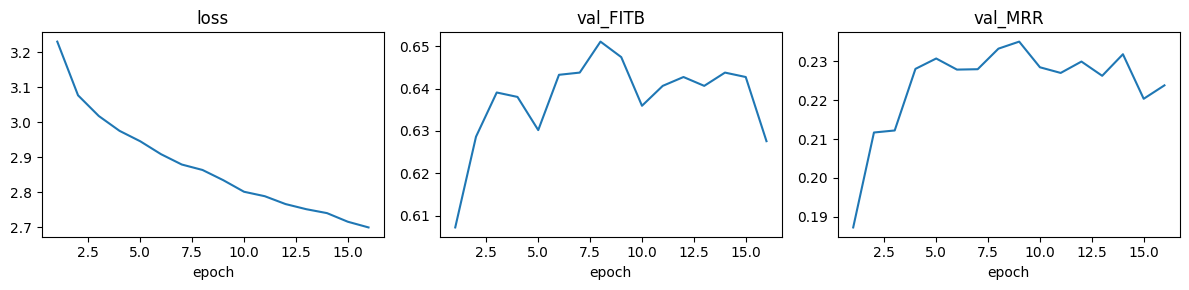

In [23]:
import matplotlib.pyplot as plt
h = pd.DataFrame(history)
cols = [c for c in h.columns if c != "epoch"]
fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3))
for ax, c in zip(np.atleast_1d(axes), cols):
    ax.plot(h["epoch"], h[c]); ax.set_title(c); ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 11. Recommend: complete an outfit (what the app does)

Give the items the beneficiary has chosen (one or more) → get the top items of each wanted type from the test catalog (same gender).

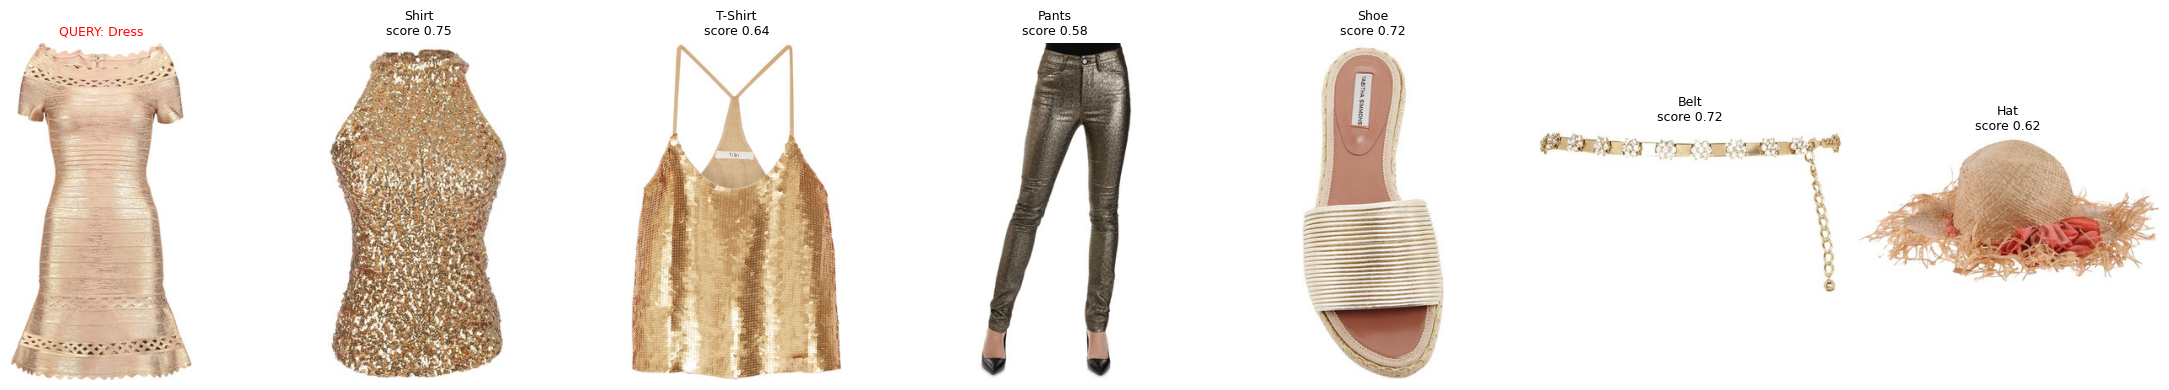

In [24]:
def recommend(selected, want_types, gender=None, catalog=None, k=3):
    """selected: list of item positions; returns {type: [(item, score), ...]}"""
    catalog = np.array(catalog if catalog is not None else
                       [x for o in split_outfits["test"] for x in outfit_items[o]])
    sel_outfits = {items[s]["outfit"] for s in selected}
    out = {}
    for t in want_types:
        cand = [c for c in catalog if items[c]["type"] == t and items[c]["outfit"] not in sel_outfits
                and (gender is None or items[c]["gender"] == gender)]
        if not cand:
            continue
        if CONFIG["MODEL"] == "outfit_transformer":
            s = scorer.fitb(selected, cand)
        else:
            s = np.mean([scorer.rank(x, cand) for x in selected], axis=0)
        top = np.argsort(-s)[:k]
        out[t] = [(cand[i], float(s[i])) for i in top]
    return out

QUERY_TYPE, GENDER = "Dress", "women"     # or "women"
WANT = ["Shirt", "T-Shirt", "Pants", "Shoe", "Belt", "Hat"]
rq = random.Random()
test_items = [x for o in split_outfits["test"] for x in outfit_items[o]]
query = rq.choice([x for x in test_items if items[x]["type"] == QUERY_TYPE and items[x]["gender"] == GENDER])
recs = recommend([query], [t for t in WANT if t in TYPE_ID], gender=GENDER)

fig, axes = plt.subplots(1, len(recs) + 1, figsize=(3.2 * (len(recs) + 1), 4))
axes[0].imshow(item_image(query)); axes[0].set_title(f"QUERY: {QUERY_TYPE}", fontsize=9, color="red")
for ax, (t, lst) in zip(axes[1:], recs.items()):
    k, s = lst[0]
    ax.imshow(item_image(k)); ax.set_title(f"{t}\nscore {s:.2f}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 12. Use with real Madad items (image + Gemini `aiDescription`)

For the app: when a donor uploads an item, compute its feature vector once (`item_vector`) and store it (and, for the transformer, its candidate embedding `cand_vector`) with the item. A recommendation = one `query` call + a dot product against stored vectors of the wanted type — fast enough for a small API (FastAPI / Cloud Run) on CPU.

In [25]:
def item_vector(image_path, description):
    im, tx = encoder([Image.open(image_path).convert("RGB")], [description])
    v = np.concatenate([im, tx], 1) if CONFIG["USE_TEXT"] else im
    return torch.from_numpy(v.astype(np.float32)).to(device)

@torch.no_grad()
def cand_vector(vec, type_name):
    return model.cand(vec, torch.tensor([TYPE_ID[type_name]], device=device))[0]

@torch.no_grad()
def compatibility(img1, desc1, type1, img2, desc2, type2):
    """Calibrated probability that two new items go together."""
    v1, v2 = item_vector(img1, desc1), item_vector(img2, desc2)
    t1, t2 = torch.tensor([TYPE_ID[type1]], device=device), torch.tensor([TYPE_ID[type2]], device=device)
    if CONFIG["MODEL"] == "outfit_transformer":
        no_pad = torch.zeros(1, 1, dtype=torch.bool, device=device)
        q1 = model.query(v1[:, None], t1[:, None], no_pad, t2)
        q2 = model.query(v2[:, None], t2[:, None], no_pad, t1)
        raw = float(((q1 * model.cand(v2, t2)).sum() + (q2 * model.cand(v1, t1)).sum()) / 2)
    elif CONFIG["MODEL"] == "type_aware":
        raw = float(model.sim(model.embed(v1), model.embed(v2), model.mask(t1, t2)))
    else:
        raw = float((torch.sigmoid(model(v1, v2)) + torch.sigmoid(model(v2, v1))) / 2)
    return float(calib.predict_proba([[raw]])[0, 1])

# print(compatibility("Examples/image_1.jpg", "A white short sleeve T-shirt", "T-Shirt",
#                     "Examples/image_2.jpg", "Black wide leg trousers", "Pants"))

## 13. Compare the models (run after training both)

This section only reads the saved files in `results/`, so it can be run on its own. It needs **at least two experiments run with the same data settings** (same SEED / ALLOWED_TYPES / DEDUP / STRICT_NO_LEAK / NEG_SAME_GENDER). Then both models answered **exactly the same test questions**, which is checked with `qset_id`.

**Which metric answers what:**

| Metric | Question | Notes |
|---|---|---|
| **AUC** (main) | Does the model give compatible pairs a higher score than incompatible ones? | 0.5 = random. Does not depend on the threshold. |
| PR-AUC | Same, focusing on the positives | Random = 0.25 (1 positive : 3 negatives). |
| Accuracy | % of pairs classified correctly | **Misleading here:** always saying "not compatible" gives 0.75. Report it, but use Balanced Accuracy / F1. |
| Balanced Accuracy | Mean of recall on positives and on negatives | 0.5 = random. |
| Precision / Recall / F1 | Quality of the "compatible" answers | Threshold chosen on validation. |
| **FITB** (main) | Pick the missing item out of 4 | Random = 0.25. The usual "accuracy" for outfit models (Vasileva et al., 2018). |
| **HR@10 / NDCG@10 / MRR** | Is the right item near the top of 100 candidates? | Closest to what the app shows. Random HR@10 = 0.10. |

**Significance:** 95% bootstrap confidence intervals (1000 resamples of the test questions), plus a paired test of model B vs model A on the same questions: McNemar for FITB, Wilcoxon for reciprocal rank, paired bootstrap for AUC. p < 0.05 means the difference is not just luck.

V2_mlp_fashionclip               model=pair_mlp  clip=patrickjohncyh/fashion-clip  qset=282a0b52b46b
V4_typeaware_fashionclip         model=type_aware  clip=patrickjohncyh/fashion-clip  qset=282a0b52b46b


,AUC,PR_AUC,Accuracy,Balanced_Acc,Precision,Recall,F1,FITB,HR@10,NDCG@10,MRR
V2_mlp_fashionclip,0.7513 [0.747-0.757],0.5311,0.6731,0.6801,0.4094,0.6941,0.5150,0.6293 [0.608-0.652],0.3705 [0.351-0.391],0.2036 [0.191-0.217],0.1757 [0.165-0.188]
V4_typeaware_fashionclip,0.7452 [0.740-0.750],0.5220,0.6924,0.6760,0.4242,0.6433,0.5112,0.6517 [0.631-0.673],0.3885 [0.366-0.410],0.2273 [0.213-0.242],0.2002 [0.187-0.213]


,FITB diff,FITB p (McNemar),MRR diff,MRR p (Wilcoxon),AUC diff,AUC p (bootstrap)
V4_typeaware_fashionclip vs V2_mlp_fashionclip,0.0224,0.0488,0.0244,0.0,-0.0062,0.002


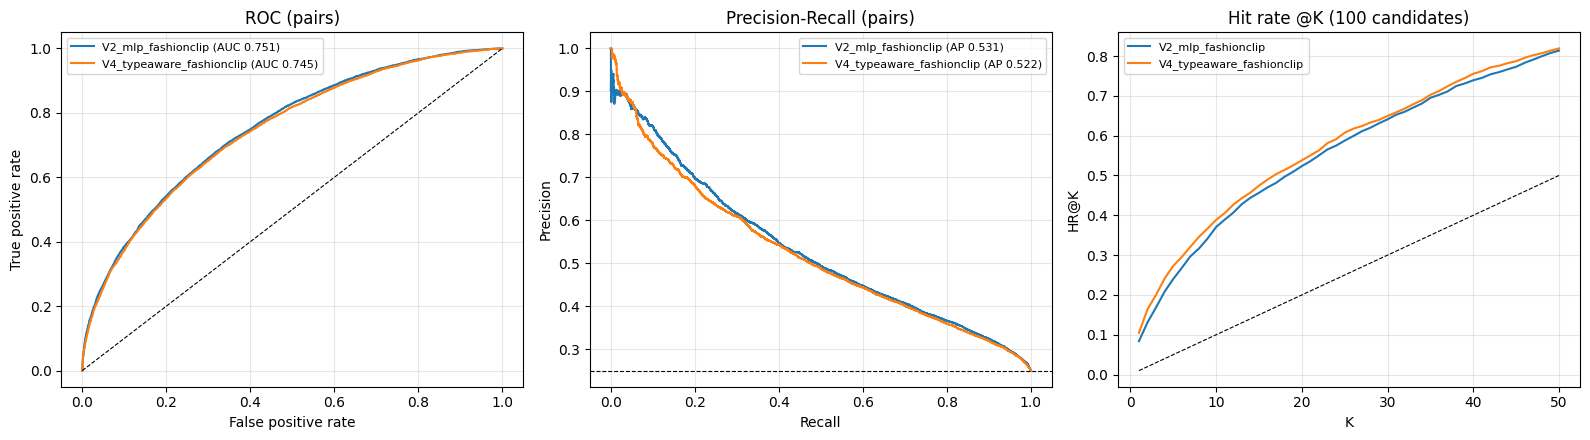

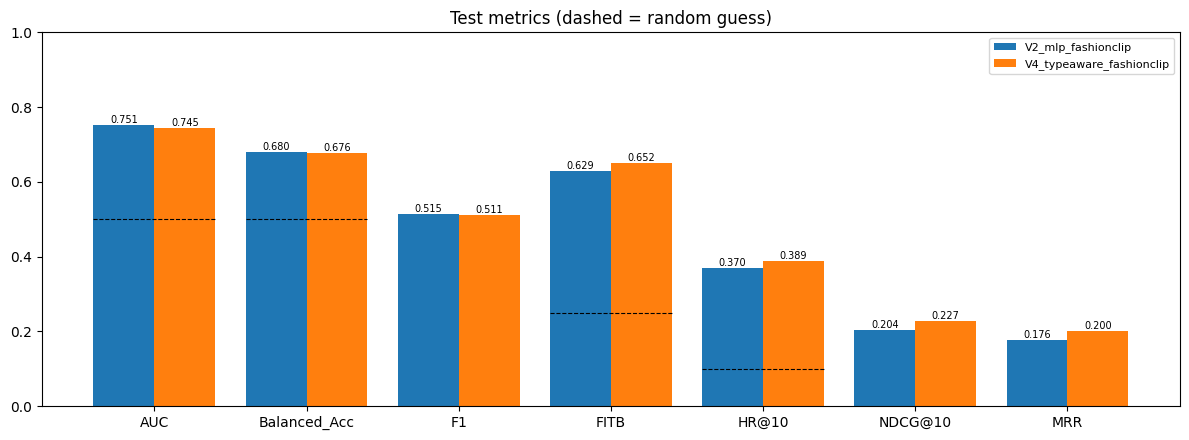

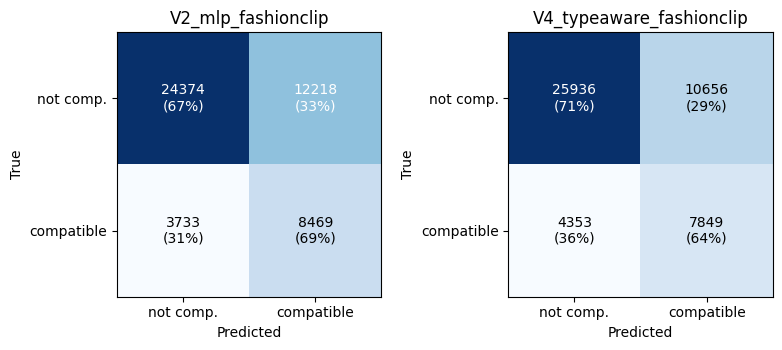

In [26]:
import os, glob
import numpy as np
import pandas as pd
from collections import defaultdict
from IPython.display import display
import matplotlib.pyplot as plt
from scipy.stats import binomtest, wilcoxon
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score)

def metrics_from_ranks(ranks, K=10):   # same as section 7 (so this cell runs on its own)
    ranks = np.asarray(ranks)
    return {f"HR@{K}": float(np.mean(ranks <= K)),
            f"NDCG@{K}": float(np.mean(np.where(ranks <= K, 1 / np.log2(ranks + 1), 0))),
            "MRR": float(np.mean(1 / ranks))}

# Choose which experiments to compare (None = all saved). The FIRST one is the reference (baseline).
COMPARE = None   # e.g. ["V1_mlp_clip", "V2_mlp_fashionclip", "V3_transformer_fashionclip"]

runs = {}
for f in sorted(glob.glob("results/scores_*.npz")):
    name = os.path.basename(f)[len("scores_"):-4]
    if COMPARE is None or name in COMPARE:
        d = np.load(f, allow_pickle=True)
        runs[name] = {k: d[k] for k in d.files}
if COMPARE:
    runs = {k: runs[k] for k in COMPARE if k in runs}
assert len(runs) >= 2, "Train at least two experiments first (change EXP_NAME / MODEL and run all)."

qsets = {str(r["qset_id"]) for r in runs.values()}
if len(qsets) > 1:
    print("WARNING: these experiments used DIFFERENT test questions (different data settings).\n"
          "         The table is still shown, but the paired tests are not valid.")
for name, r in runs.items():
    print(f"{name:32s} model={r['model']}  clip={r['clip']}  qset={r['qset_id']}")

def point_metrics(r):
    y, s = r["y_true"], r["y_score"]
    p = (s >= float(r["threshold"])).astype(int)
    return {"AUC": roc_auc_score(y, s), "PR_AUC": average_precision_score(y, s),
            "Accuracy": accuracy_score(y, p), "Balanced_Acc": balanced_accuracy_score(y, p),
            "Precision": precision_score(y, p, zero_division=0), "Recall": recall_score(y, p, zero_division=0),
            "F1": f1_score(y, p, zero_division=0), "FITB": r["fitb_hits"].mean(),
            **metrics_from_ranks(r["ranks"])}

def bootstrap_ci(r, n_boot=1000, seed=0):
    rs = np.random.default_rng(seed)
    y, s = r["y_true"], r["y_score"]
    out = defaultdict(list)
    for _ in range(n_boot):
        i = rs.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            out["AUC"].append(roc_auc_score(y[i], s[i]))
        out["FITB"].append(r["fitb_hits"][rs.integers(0, len(r["fitb_hits"]), len(r["fitb_hits"]))].mean())
        rk = r["ranks"][rs.integers(0, len(r["ranks"]), len(r["ranks"]))]
        for k, v in metrics_from_ranks(rk).items():
            out[k].append(v)
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in out.items()}

# ---------- 1) main table with 95% CI ----------
table = {}
for name, r in runs.items():
    m, ci = point_metrics(r), bootstrap_ci(r)
    table[name] = {k: (f"{v:.4f}" + (f" [{ci[k][0]:.3f}-{ci[k][1]:.3f}]" if k in ci else "")) for k, v in m.items()}
table = pd.DataFrame(table).T
display(table)
table.to_csv("results/comparison_table.csv")

# ---------- 2) paired significance tests vs the first experiment ----------
def paired_tests(A, B, n_boot=1000, seed=0):
    out = {}
    # FITB: McNemar exact test on questions where exactly one model is right
    b01 = int(((A["fitb_hits"] == 0) & (B["fitb_hits"] == 1)).sum())
    b10 = int(((A["fitb_hits"] == 1) & (B["fitb_hits"] == 0)).sum())
    out["FITB diff"] = B["fitb_hits"].mean() - A["fitb_hits"].mean()
    out["FITB p (McNemar)"] = binomtest(b01, b01 + b10, 0.5).pvalue if b01 + b10 else 1.0
    # MRR: Wilcoxon signed-rank on reciprocal ranks
    ra, rb = 1 / A["ranks"], 1 / B["ranks"]
    out["MRR diff"] = rb.mean() - ra.mean()
    out["MRR p (Wilcoxon)"] = wilcoxon(rb, ra).pvalue if np.any(ra != rb) else 1.0
    # AUC: paired bootstrap on the same pairs
    rs = np.random.default_rng(seed)
    y = A["y_true"]
    diffs = []
    for _ in range(n_boot):
        i = rs.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            diffs.append(roc_auc_score(y[i], B["y_score"][i]) - roc_auc_score(y[i], A["y_score"][i]))
    diffs = np.array(diffs)
    out["AUC diff"] = roc_auc_score(y, B["y_score"]) - roc_auc_score(y, A["y_score"])
    out["AUC p (bootstrap)"] = min(1.0, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean()))
    return out

names = list(runs)
if len(qsets) == 1:
    ref = names[0]
    sig = pd.DataFrame({f"{n} vs {ref}": paired_tests(runs[ref], runs[n]) for n in names[1:]}).T
    display(sig.round(4))
    sig.to_csv("results/significance.csv")

# ---------- 3) charts ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, r in runs.items():
    fpr, tpr, _ = roc_curve(r["y_true"], r["y_score"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(r['y_true'], r['y_score']):.3f})")
    pr, rc, _ = precision_recall_curve(r["y_true"], r["y_score"])
    axes[1].plot(rc, pr, label=f"{name} (AP {average_precision_score(r['y_true'], r['y_score']):.3f})")
    ks = np.arange(1, 51)
    axes[2].plot(ks, [(r["ranks"] <= k).mean() for k in ks], label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set(title="ROC (pairs)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(0.25, color="k", ls="--", lw=0.8); axes[1].set(title="Precision-Recall (pairs)", xlabel="Recall", ylabel="Precision")
axes[2].plot(ks, ks / 100, "k--", lw=0.8); axes[2].set(title="Hit rate @K (100 candidates)", xlabel="K", ylabel="HR@K")
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("results/comparison_curves.png", dpi=200); plt.show()

# bar chart of the main metrics (with random-guess lines)
main = ["AUC", "Balanced_Acc", "F1", "FITB", "HR@10", "NDCG@10", "MRR"]
chance = {"AUC": 0.5, "Balanced_Acc": 0.5, "FITB": 0.25, "HR@10": 0.10}
vals = pd.DataFrame({n: point_metrics(r) for n, r in runs.items()}).T[main]
x, w = np.arange(len(main)), 0.8 / len(runs)
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, (n, row) in enumerate(vals.iterrows()):
    bars = ax.bar(x + i * w - 0.4 + w / 2, row.values, w, label=n)
    ax.bar_label(bars, fmt="%.3f", fontsize=7)
for j, m in enumerate(main):
    if m in chance:
        ax.hlines(chance[m], j - 0.4, j + 0.4, colors="k", linestyles="--", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(main); ax.set_ylim(0, 1); ax.legend(fontsize=8)
ax.set_title("Test metrics (dashed = random guess)")
plt.tight_layout(); plt.savefig("results/comparison_bars.png", dpi=200); plt.show()

# confusion matrices at each model's validation threshold
fig, axes = plt.subplots(1, len(runs), figsize=(4 * len(runs), 3.6))
for ax, (name, r) in zip(np.atleast_1d(axes), runs.items()):
    cm = confusion_matrix(r["y_true"], (r["y_score"] >= float(r["threshold"])).astype(int))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}\n({v / cm[i].sum():.0%})", ha="center", va="center",
                color="white" if v > cm.max() / 2 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["not comp.", "compatible"],
           yticklabels=["not comp.", "compatible"], xlabel="Predicted", ylabel="True", title=name)
plt.tight_layout(); plt.savefig("results/comparison_confusion.png", dpi=200); plt.show()

In [27]:
import json
from collections import Counter
cnt, pair = Counter(), Counter()
for o in split_outfits["train"]:
    ts = {items[k]["type"] for k in outfit_items[o]}
    for a in ts:
        cnt[a] += 1
        for b in ts:
            if a != b: pair[(a, b)] += 1
GO_WITH = {a: sorted([b for b in TYPES if b != a and pair[(a, b)] / cnt[a] >= 0.05],
                     key=lambda b: -pair[(a, b)]) for a in TYPES}
for a in TYPES:
    print(f"{a:8s} ->", ", ".join(f"{b} {pair[(a,b)]/cnt[a]:.0%}" for b in GO_WITH[a]))
json.dump(GO_WITH, open("results/type_cooccurrence.json", "w"), indent=1)

Bag      -> Shoe 68%, Pants 31%, Dress 25%, Shirt 24%, Sweater 18%, Jacket 18%, Skirt 17%, Coat 13%, Glasses 13%, T-Shirt 13%, Hat 7%, Watch 6%
Belt     -> Shoe 67%, Bag 54%, Shirt 37%, Pants 35%, Jacket 21%, Skirt 21%, Glasses 15%, Dress 14%, Sweater 14%, T-Shirt 14%, Coat 12%, Hat 9%, Watch 7%, Shawl 5%
Coat     -> Shoe 69%, Bag 63%, Pants 32%, Dress 25%, Shirt 21%, Sweater 21%, Skirt 15%, Glasses 10%, Hat 9%, T-Shirt 9%, Shawl 8%, Watch 6%
Dress    -> Shoe 71%, Bag 65%, Jacket 14%, Coat 13%, Glasses 10%, Hat 6%
Glasses  -> Shoe 66%, Bag 58%, Pants 35%, Shirt 26%, Sweater 18%, Dress 18%, Jacket 16%, T-Shirt 16%, Skirt 15%, Hat 10%, Coat 9%, Watch 7%
Gloves   -> Shoe 72%, Bag 51%, Pants 34%, Coat 32%, Sweater 25%, Hat 21%, Dress 20%, Shawl 19%, Jacket 16%, Shirt 16%, Skirt 15%, Glasses 13%, T-Shirt 9%
Hat      -> Shoe 64%, Bag 50%, Pants 39%, Shirt 22%, Sweater 20%, Dress 18%, T-Shirt 17%, Glasses 16%, Jacket 15%, Coat 13%, Skirt 11%, Watch 7%, Shawl 7%
Jacket   -> Shoe 67%, Bag 57%, 